<center><h1>Zambrano_Claudia_HW7</h1></center>

Name: Claudia Zambrano
<br>
Github Username: claudia-z712
<br>
USC ID: 82249488661

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score, hamming_loss, accuracy_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from PIL import Image

### (a) Download the Anuran Calls (MFCCs) Data Set

In [30]:
df = pd.read_csv('Frogs_MFCCs.csv')
df.head()

# Splitting the dataset 70% for training
train_df, test_df = train_test_split(df, train_size=0.7, random_state=10)

print(f"Training set size: {train_df.shape}")
print(f"Test set size: {test_df.shape}")

Training set size: (5036, 26)
Test set size: (2159, 26)


### (b) Train a classifier for each label

#### (i) Research

Hamming score measures the average porportion of correct labels per instance, while hamming loss measures the fraction of wrong labels  across all instances and classes. In other words Hamming measures accuracy. Exact match is alot more strict, it either 0 or 1 and treats the entire set as a whole.

#### (ii) Train a SVM for each of the labels

In [31]:
# Set up so output looks cleaner (removes np.float64)
np.set_printoptions(legacy='1.25')

# Features are the 22 MFCCs columns
features = [col for col in train_df.columns if col.startswith('MFCCs_')]
targets = ['Family', 'Genus', 'Species']

X_train = train_df[features]
y_train = train_df[targets]

X_test = test_df[features]
y_test = test_df[targets]

# Define SVM parameter grid for Gaussian kernel (RBF)
param_grid = {
    'C': np.logspace(-1, 3, 5),
    'gamma': np.logspace(-3, 1, 5)
}

best_models = {}
predictions = pd.DataFrame(index=test_df.index)

for label in targets:
    print(f"Optimizing SVM for label: {label}")
    # SVC with decision_function_shape='ovr' handles multi-class via One-Vs-Rest
    svc = SVC(kernel='rbf', decision_function_shape='ovr')
    clf = GridSearchCV(svc, param_grid, cv=10, n_jobs=-1)
    clf.fit(X_train, y_train[label])

    best_models[label] = clf.best_estimator_
    predictions[label] = clf.predict(X_test)
    print(f"Best Parameters for {label}: {clf.best_params_}")

# Compute exact match ratio (subset accuracy)
# We count a prediction as correct only if all labels match the ground truth for that row
exact_matches = (predictions == y_test).all(axis=1)
exact_match_ratio = np.mean(exact_matches)

# Compute hamming loss for each label, then average them
hamming_losses = []
for label in targets:
    loss = hamming_loss(y_test[label], predictions[label])
    hamming_losses.append(loss)
mean_hamming_loss = np.mean(hamming_losses)

print(f"\nExact Match Ratio (Subset Accuracy): {exact_match_ratio:.4f}")
print(f"Hamming Loss: {mean_hamming_loss:.4f}")

Optimizing SVM for label: Family
Best Parameters for Family: {'C': 100.0, 'gamma': 1.0}
Optimizing SVM for label: Genus
Best Parameters for Genus: {'C': 100.0, 'gamma': 1.0}
Optimizing SVM for label: Species
Best Parameters for Species: {'C': 100.0, 'gamma': 1.0}

Exact Match Ratio (Subset Accuracy): 0.9861
Hamming Loss: 0.0099


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [12]:
# Define the search space for C
param_grid = {
    'linearsvc__C': np.logspace(-3, 3, 7)
}

best_models = {}
predictions = pd.DataFrame(index=test_df.index)

for label in targets:
    print(f"Optimizing L1-penalized LinearSVM for label: {label}")
    clf = GridSearchCV(pipeline, param_grid, cv=10, n_jobs=-1)
    clf.fit(X_train, y_train[label])

    best_models[label] = clf.best_estimator_
    predictions[label] = clf.predict(X_test)
    print(f"Best Parameters for {label}: {clf.best_params_}")

# Compute accuracy
exact_matches = (predictions == y_test).all(axis=1)
exact_match_ratio = np.mean(exact_matches)

# Compute hamming loss for each label, then average them
hamming_losses = []
for label in targets:
    loss = hamming_loss(y_test[label], predictions[label])
    hamming_losses.append(loss)
mean_hamming_loss = np.mean(hamming_losses)

print(f"\nExact Match Ratio (Subset Accuracy): {exact_match_ratio:.4f}")
print(f"Hamming Loss: {mean_hamming_loss:.4f}")

Optimizing L1-penalized LinearSVM for label: Family
Best Parameters for Family: {'linearsvc__C': 10.0}
Optimizing L1-penalized LinearSVM for label: Genus
Best Parameters for Genus: {'linearsvc__C': 100.0}
Optimizing L1-penalized LinearSVM for label: Species
Best Parameters for Species: {'linearsvc__C': 10.0}

Exact Match Ratio (Subset Accuracy): 0.9176
Hamming Loss: 0.0522


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [16]:
# Define search space for C
param_grid = {
    'linearsvc__C': np.logspace(-3, 3, 7)
}

best_models_smote = {} 
predictions_smote = pd.DataFrame(index=test_df.index)

for label in targets:
    print(f"Applying SMOTE and optimizing L1-penalized LinearSVM for label: {label}")
    
    # Apply SMOTE to training data for the current target
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train[label])
    
    # Hyperparameter tuning using 10-fold CV on the resampled data
    clf = GridSearchCV(pipeline_smote, param_grid, cv=10, n_jobs=-1)
    clf.fit(X_train_res, y_train_res)
    
    best_models_smote[label] = clf.best_estimator_
    predictions_smote[label] = clf.predict(X_test)
    print(f"Best Parameters for {label}: {clf.best_params_}")

# Compute exact match ratio (subset accuracy)
exact_matches_smote = (predictions_smote == y_test).all(axis=1)
exact_match_ratio_smote = np.mean(exact_matches_smote)

# Compute hamming loss for each label, then average them
hamming_losses_smote = [hamming_loss(y_test[label], predictions_smote[label]) for label in targets]
mean_hamming_loss_smote = np.mean(hamming_losses_smote)

print(f"\n--- Results WITH SMOTE ---")
print(f"Exact Match Ratio (Subset Accuracy): {exact_match_ratio_smote:.4f}")
print(f"Hamming Loss: {mean_hamming_loss_smote:.4f}")

Applying SMOTE and optimizing L1-penalized LinearSVM for label: Family
Best Parameters for Family: {'linearsvc__C': 1000.0}
Applying SMOTE and optimizing L1-penalized LinearSVM for label: Genus
Best Parameters for Genus: {'linearsvc__C': 1000.0}
Applying SMOTE and optimizing L1-penalized LinearSVM for label: Species
Best Parameters for Species: {'linearsvc__C': 100.0}

--- Results WITH SMOTE ---
Exact Match Ratio (Subset Accuracy): 0.8773
Hamming Loss: 0.0631


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

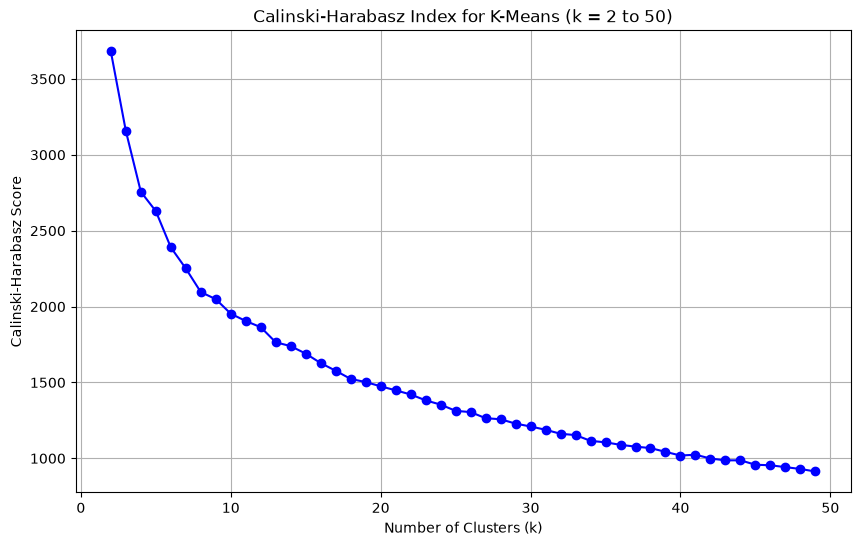

The optimal number of clusters according to the CH index is: 2


In [24]:
# Extract the 22 MFCCs features from the entire dataset
X_all = df[features]

k_values = list(range(2, 50))
ch_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=7, n_init=10)
    labels = kmeans.fit_predict(X_all)
    score = calinski_harabasz_score(X_all, labels)
    ch_scores.append(score)

# Plot the Calinski-Harabasz scores
plt.figure(figsize=(10, 6))
plt.plot(k_values, ch_scores, marker='o', linestyle='-', color='b')
plt.title('Calinski-Harabasz Index for K-Means (k = 2 to 50)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Calinski-Harabasz Score')
plt.grid(True)
plt.show()

# Find the optimal k based on the maximum CH score
best_k = k_values[np.argmax(ch_scores)]
print(f"The optimal number of clusters according to the CH index is: {best_k}")


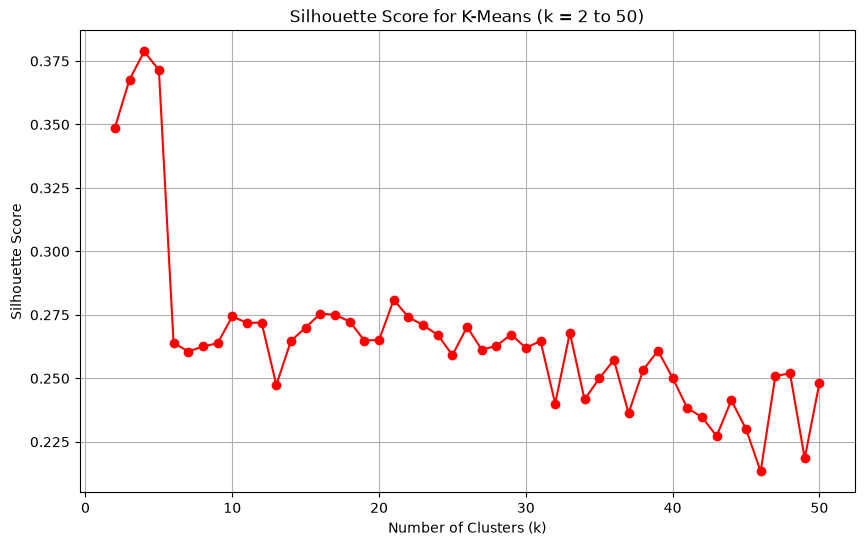

The optimal number of clusters according to the Silhouette index is: 4


In [26]:
# Extract the 22 MFCCs features from the entire dataset
X_all = df[features]

k_values = list(range(2, 51))
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=7, n_init=10)
    labels = kmeans.fit_predict(X_all)
    score = silhouette_score(X_all, labels)
    silhouette_scores.append(score)

# Plot the Silhouette scores
plt.figure(figsize=(10, 6))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='r')
plt.title('Silhouette Score for K-Means (k = 2 to 50)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

# Find the optimal k based on the maximum Silhouette score
best_k_sil = k_values[np.argmax(silhouette_scores)]
print(f"The optimal number of clusters according to the Silhouette index is: {best_k_sil}")

In [27]:
# Features are the 22 MFCCs columns
features = [col for col in df.columns if col.startswith('MFCCs_')]
targets = ['Family', 'Genus', 'Species']

X = df[features]
y = df[targets]

hamming_distances = []
best_ks = []

print("Running K-Means 50 times...")
for run in range(1, 51):
    best_silhouette = -1
    best_k = 2
    
    # Silhouette score requires at least 2 clusters
    for k in range(2, 51):
        kmeans = KMeans(n_clusters=k, random_state=run, n_init=10)
        cluster_labels = kmeans.fit_predict(X)
        score = silhouette_score(X, cluster_labels)
        if score > best_silhouette:
            best_silhouette = score
            best_k = k
            
    best_ks.append(best_k)
    
    # Train K-Means with the best k for this iteration
    best_kmeans = KMeans(n_clusters=best_k, random_state=run, n_init=10)
    cluster_labels = best_kmeans.fit_predict(X)
    
    # Majority label assignment for each cluster
    predictions = pd.DataFrame(index=df.index, columns=targets)
    for cluster in range(best_k):
        cluster_indices = (cluster_labels == cluster)
        if np.any(cluster_indices):
            for target in targets:
                majority_label = y.loc[cluster_indices, target].value_counts().idxmax()
                predictions.loc[cluster_indices, target] = majority_label
                
    # Calculate Hamming distance (Hamming Loss) for this run
    losses = []
    for target in targets:
        loss = hamming_loss(y[target], predictions[target])
        losses.append(loss)
    
    # We represent Hamming distance as the average hamming loss across labels
    hamming_distances.append(np.mean(losses))
    print(f"Iteration {run:02d}: Best k = {best_k}, Hamming Loss = {hamming_distances[-1]:.4f}")

avg_hamming = np.mean(hamming_distances)
std_hamming = np.std(hamming_distances)

print(f"\nAverage Hamming Distance over 50 runs: {avg_hamming:.4f}")
print(f"Standard Deviation of Hamming Distance over 50 runs: {std_hamming:.4f}")

Running K-Means 50 times...
Iteration 01: Best k = 4, Hamming Loss = 0.2224
Iteration 02: Best k = 4, Hamming Loss = 0.2451
Iteration 03: Best k = 4, Hamming Loss = 0.2224
Iteration 04: Best k = 4, Hamming Loss = 0.2224
Iteration 05: Best k = 4, Hamming Loss = 0.2224
Iteration 06: Best k = 4, Hamming Loss = 0.2224
Iteration 07: Best k = 4, Hamming Loss = 0.2224
Iteration 08: Best k = 4, Hamming Loss = 0.2224
Iteration 09: Best k = 4, Hamming Loss = 0.2224
Iteration 10: Best k = 4, Hamming Loss = 0.2224
Iteration 11: Best k = 4, Hamming Loss = 0.2219
Iteration 12: Best k = 4, Hamming Loss = 0.2225
Iteration 13: Best k = 4, Hamming Loss = 0.2224
Iteration 14: Best k = 4, Hamming Loss = 0.2224
Iteration 15: Best k = 4, Hamming Loss = 0.2224
Iteration 16: Best k = 4, Hamming Loss = 0.2224
Iteration 17: Best k = 4, Hamming Loss = 0.2224
Iteration 18: Best k = 4, Hamming Loss = 0.2224
Iteration 19: Best k = 4, Hamming Loss = 0.2219
Iteration 20: Best k = 4, Hamming Loss = 0.2224
Iteration 21

### (b) Determine which family is the majority

In [34]:
# Features and targets
features = [col for col in df.columns if col.startswith('MFCCs_')]
X = df[features]
targets = ['Family', 'Genus', 'Species']
y = df[targets]

# Fit K-Means with k = 4
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X)

# Majority label mapping for all targets
predictions = pd.DataFrame(index=df.index, columns=targets)

print("--- Cluster Majority Label Assignment ---")
for cluster in range(4):
    cluster_indices = (cluster_labels == cluster)
    if np.any(cluster_indices):
        print(f"\nCluster {cluster} (Size: {np.sum(cluster_indices)}):")
        for target in targets:
            counts = y.loc[cluster_indices, target].value_counts()
            majority_label = counts.idxmax()
            count = counts.max()
            total = counts.sum()
            predictions.loc[cluster_indices, target] = majority_label
            print(f"  Majority {target}: '{majority_label}' ({count}/{total} samples, {count/total*100:.2f}%)")

--- Cluster Majority Label Assignment ---

Cluster 0 (Size: 3568):
  Majority Family: 'Leptodactylidae' (3467/3568 samples, 97.17%)
  Majority Genus: 'Adenomera' (3466/3568 samples, 97.14%)
  Majority Species: 'AdenomeraHylaedactylus' (3466/3568 samples, 97.14%)

Cluster 1 (Size: 614):
  Majority Family: 'Hylidae' (590/614 samples, 96.09%)
  Majority Genus: 'Hypsiboas' (542/614 samples, 88.27%)
  Majority Species: 'HypsiboasCinerascens' (452/614 samples, 73.62%)

Cluster 2 (Size: 1031):
  Majority Family: 'Dendrobatidae' (500/1031 samples, 48.50%)
  Majority Genus: 'Ameerega' (500/1031 samples, 48.50%)
  Majority Species: 'Ameeregatrivittata' (500/1031 samples, 48.50%)

Cluster 3 (Size: 1982):
  Majority Family: 'Hylidae' (1245/1982 samples, 62.82%)
  Majority Genus: 'Hypsiboas' (1038/1982 samples, 52.37%)
  Majority Species: 'HypsiboasCordobae' (1018/1982 samples, 51.36%)


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [37]:
# Calculate and print Hamming Loss/Distance for each target
print("\n--- Hamming Loss (Distance) Metrics ---")
individual_losses = []
for target in targets:
    loss = hamming_loss(y[target], predictions[target])
    individual_losses.append(loss)
    print(f"Hamming Loss for {target}: {loss:.4f}")

print(f"Average Hamming Distance (Loss) across all 3 labels: {np.mean(individual_losses):.4f}")

# Compute Hamming score (which is individual label accuracy)
print("--- Hamming Score (Accuracy) Metrics ---")
individual_scores = []
for target in targets:
    # Hamming score for a single label is simply its accuracy
    score = accuracy_score(y[target], predictions[target])
    individual_scores.append(score)
    print(f"Hamming Score for {target}: {score:.4f}")

mean_hamming_score = np.mean(individual_scores)
print(f"Average Hamming Score across all 3 labels: {mean_hamming_score:.4f}")

# Verification that Hamming Score + Hamming Loss = 1
print("\nVerification (Hamming Score + Hamming Loss):")
for i, target in enumerate(targets):
    print(f"  {target}: {individual_scores[i]:.4f} + {individual_losses[i]:.4f} = {individual_scores[i] + individual_losses[i]:.4f}")



--- Hamming Loss (Distance) Metrics ---
Hamming Loss for Family: 0.1936
Hamming Loss for Genus: 0.2292
Hamming Loss for Species: 0.2445
Average Hamming Distance (Loss) across all 3 labels: 0.2224
--- Hamming Score (Accuracy) Metrics ---
Hamming Score for Family: 0.8064
Hamming Score for Genus: 0.7708
Hamming Score for Species: 0.7555
Average Hamming Score across all 3 labels: 0.7776

Verification (Hamming Score + Hamming Loss):
  Family: 0.8064 + 0.1936 = 1.0000
  Genus: 0.7708 + 0.2292 = 1.0000
  Species: 0.7555 + 0.2445 = 1.0000


## 3. ISLR 12.6.2

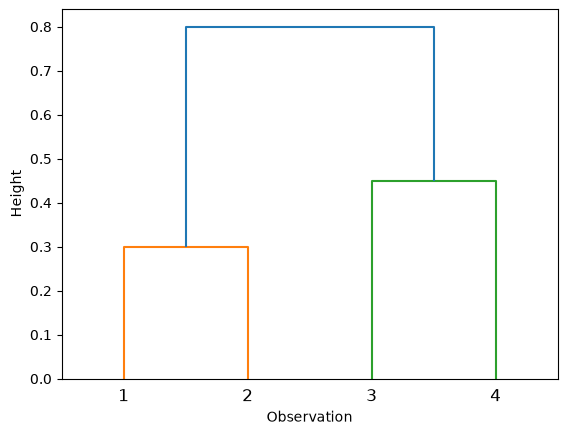

In [41]:
# Problem A.
D = np.array([
    [0,    0.3,  0.4,  0.7],
    [0.3,  0,    0.5,  0.8],
    [0.4,  0.5,  0,    0.45],
    [0.7,  0.8,  0.45, 0]
])

Z = linkage(squareform(D), method='complete')
dendrogram(Z, labels=[1, 2, 3, 4])
plt.ylabel("Height")
plt.xlabel("Observation")
plt.show()

#Fusion occurs at h= 0.3, 0.45, 0.8


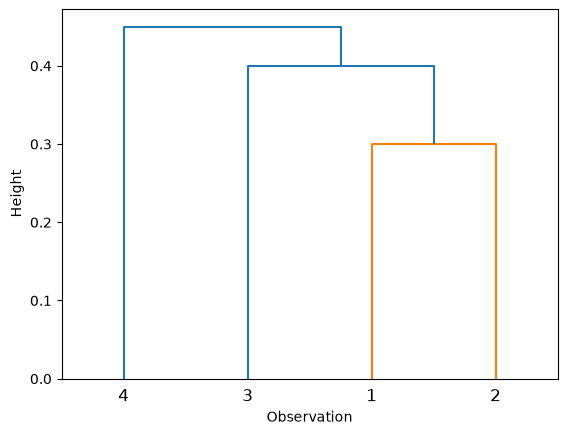

In [42]:
# Problem B
Z = linkage(squareform(D), method='single')
dendrogram(Z, labels=[1, 2, 3, 4])
plt.ylabel("Height")
plt.xlabel("Observation")
plt.show()

# Fusion occurs at h= 0.3, 0.4, 0.45


Part C.)

If we were to take the the dendrogram in a and split it between two clusters we could have observations 1 and 2 in one and 3 and 4 in the other.

Part D.)

For the dendrogram in part B, one cluster would contain observation 4, while the other cluster would contain 1, 2, and 3.

In [48]:
img = Image.open("PartE.jpg")
img.show()
